# Practice 1

# Penguins Clustering

Compare **K-Means** and **DBSCAN** using the instructor's workflow.

**Steps:** load the dataset, keep the target label separate, perform exploratory data analysis (EDA), scale the features, select and run K-Means, inspect DBSCAN parameters, compare the clustering results, and evaluate the final results with `adjusted_rand_score`.

Note: `species` is not used during clustering. It is kept aside and used only during final evaluation.

## Cell 1 — Import the Libraries

Import the libraries needed for data loading, preprocessing, clustering, evaluation, and plotting.

In [3]:
# General tools for data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loading and feature preprocessing
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN

# Neighborhood search and evaluation metrics
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

## Cell 2 — Load the Dataset

Load the Penguins dataset from OpenML and remove rows that contain missing values.

In [4]:
# Load the dataset as a pandas DataFrame
penguins = fetch_openml("penguins", version=1, as_frame=True)

# Remove rows with missing values, following the current notebook's approach
df = penguins.frame.dropna()

# Display the first few rows to verify that the dataset loaded correctly
display(df.head())
print("Dataset shape:", df.shape)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


Dataset shape: (334, 7)


## Cell 3 — Separate the Target Label from the Features

Keep `species` aside for the final evaluation. Do not pass this column to the clustering models. Convert categorical feature columns to numeric columns using `get_dummies`.

In [5]:
# Keep the true labels aside; do not use them during clustering
y_true = df["species"]

# Build the feature matrix without the species column
X = df.drop(columns=["species"])

# Convert categorical features such as island and sex into numeric columns
X = pd.get_dummies(X, drop_first=True)

print("Features shape:", X.shape)
display(X.head())

Features shape: (334, 8)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE,sex__
0,39.1,18.7,181.0,3750.0,False,True,True,False
1,39.5,17.4,186.0,3800.0,False,True,False,False
2,40.3,18.0,195.0,3250.0,False,True,False,False
4,36.7,19.3,193.0,3450.0,False,True,False,False
5,39.3,20.6,190.0,3650.0,False,True,True,False


## Cell 4 — Exploratory Data Analysis (EDA)

Check the dataset dimensions, missing values, duplicate rows, ranges of the numeric features, and their distributions. At this stage, do not use `species` to analyze the clusters.

Dataset shape: (334, 8)
Missing values: 0
Duplicate feature rows: 0


,min,max
culmen_length_mm,32.1,59.6
culmen_depth_mm,13.1,21.5
flipper_length_mm,172.0,231.0
body_mass_g,2700.0,6300.0


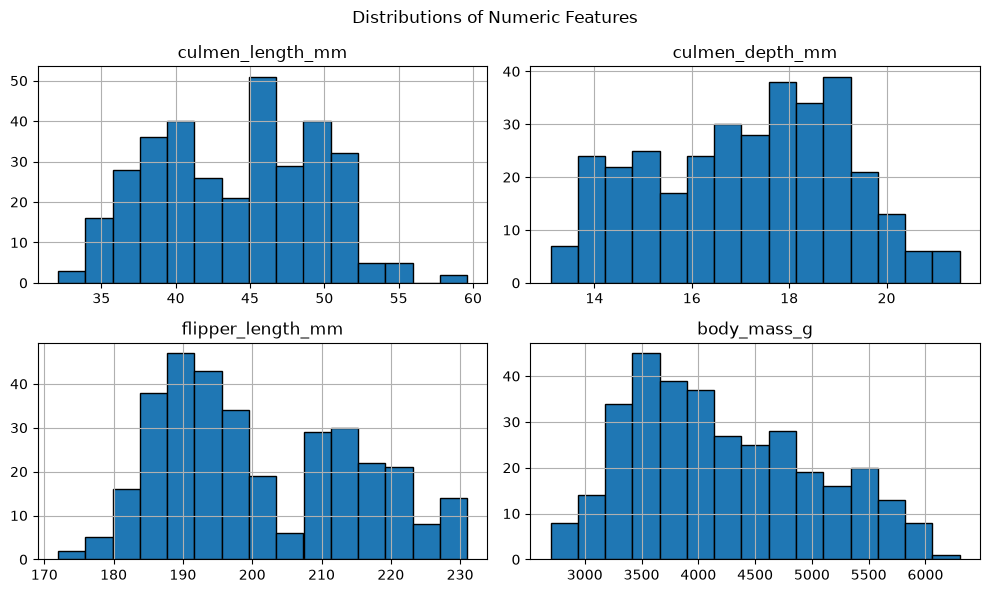

In [6]:
# Check the overall status of the feature matrix
print("Dataset shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())

# Show the minimum and maximum values of the original numeric features
numeric_features = df.select_dtypes(include=np.number).columns
display(df[numeric_features].describe().T[["min", "max"]])

# Plot histograms to inspect the distributions of the numeric features
df[numeric_features].hist(bins=15, figsize=(10, 6), edgecolor="black")
plt.suptitle("Distributions of Numeric Features")
plt.tight_layout()
plt.show()

## Cell 5 — Feature Scaling

K-Means and DBSCAN are distance-based algorithms, so scale the features with `StandardScaler` before running them.

In [7]:
# Create the scaler and apply it to the feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check that the scaled data has a mean near zero and a standard deviation near one
print("Scaled mean (approx. 0):", round(X_scaled.mean(), 4))
print("Scaled standard deviation (approx. 1):", round(X_scaled.std(), 4))

Scaled mean (approx. 0): 0.0
Scaled standard deviation (approx. 1): 1.0


## Cell 6 — Select the Number of K-Means Clusters

Calculate Inertia and the Silhouette Score for several values of `k`. Use the Elbow plot and Silhouette scores to help choose `k`. The current notebook keeps `k=3` as the final starting choice; inspect the plots as well before deciding whether it is appropriate.

,k,inertia,silhouette_score
0,2,1748.449802,0.388258
1,3,1341.592405,0.427044
2,4,1105.461647,0.413804
3,5,771.694062,0.426418


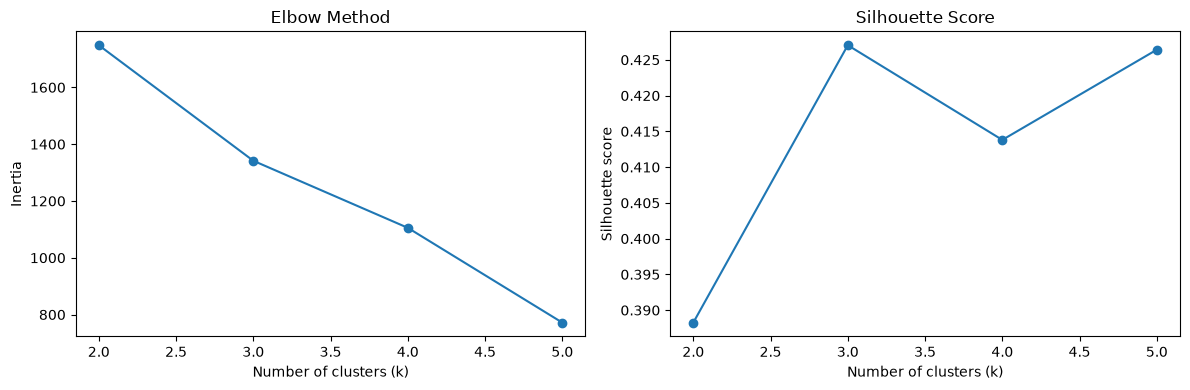

Best k by Silhouette score: 3
Final K-Means k: 3


In [8]:
# Define the values of k to compare
K_range = range(2, 6)
inertias = []
sil_scores = []

# Fit K-Means for each k and store both evaluation metrics
for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# Display the metrics in a table for numerical comparison
kmeans_results = pd.DataFrame({
    "k": list(K_range),
    "inertia": inertias,
    "silhouette_score": sil_scores
})

display(kmeans_results)

# Plot the Elbow curve and Silhouette scores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(kmeans_results["k"], kmeans_results["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    kmeans_results["k"],
    kmeans_results["silhouette_score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

# Record the k with the highest Silhouette score
best_silhouette_k = int(
    kmeans_results.loc[
        kmeans_results["silhouette_score"].idxmax(), "k"
    ]
)

print("Best k by Silhouette score:", best_silhouette_k)

# Fit the final K-Means model using the current notebook's initial choice
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_scaled)

print("Final K-Means k:", kmeans_final.n_clusters)

## Cell 7 — Profile the K-Means Clusters

The instructor's checklist requires more than creating clusters: inspect the mean feature values and the number of samples in each cluster. Use the original numeric features so the values remain interpretable.

In [9]:
# Create a table of the original numeric features and add the cluster labels
cluster_profile = df[numeric_features].copy()
cluster_profile["cluster"] = kmeans_labels

# Show the mean numeric feature values for each cluster
print("Mean numeric feature values by K-Means cluster:")
display(cluster_profile.groupby("cluster").mean().round(2))

# Show the number of samples in each cluster
print("Cluster sizes:")
display(
    cluster_profile["cluster"]
    .value_counts()
    .sort_index()
    .rename("number_of_samples")
)

Mean numeric feature values by K-Means cluster:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
cluster,,,,
0,39.04,18.45,191.53,3708.51
1,47.54,15.00,217.23,5090.62
2,42.84,18.35,192.03,3716.47


Cluster sizes:


cluster
0     47
1    120
2    167
Name: number_of_samples, dtype: int64

## Cell 8 — Create the DBSCAN k-Distance Plot

Calculate the distance from each point to its fifth nearest neighbor and sort the distances. The plot can help identify where the distances begin to increase more sharply. Use both this plot and the parameter sweep to assess `eps`.

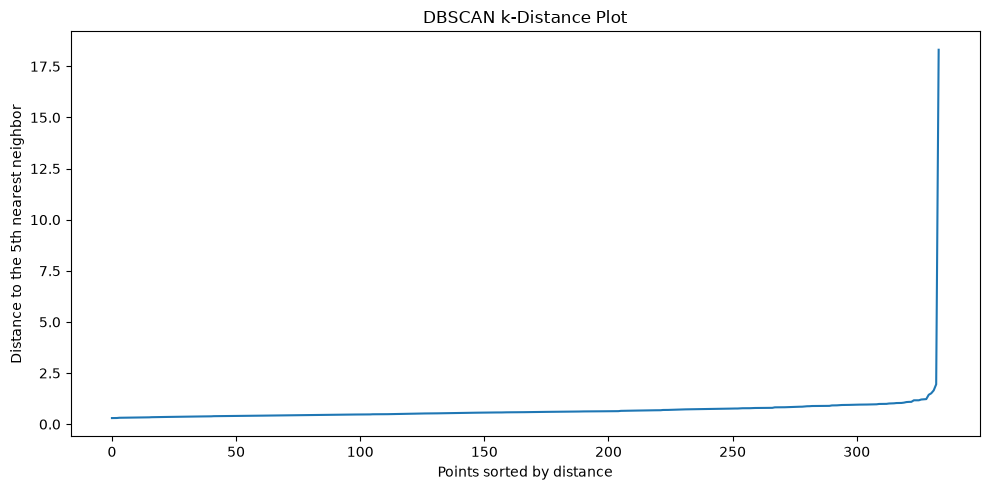

In [10]:
# Set min_samples for the DBSCAN parameter analysis
min_samples = 5

# Find the distance to the fifth nearest neighbor; the point itself is included among the neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort the fifth-neighbor distances to create the k-distance plot
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to the 5th nearest neighbor")
plt.title("DBSCAN k-Distance Plot")
plt.tight_layout()
plt.show()

## Cell 9 — Compare Several DBSCAN `eps` Values

The instructor's checklist asks you to test DBSCAN with multiple `eps` values. For each value, record the number of clusters and the number and percentage of noise points. Use this table together with the k-distance plot to choose a suitable parameter.

In [11]:
# Values of eps to compare; keep min_samples fixed for all experiments
eps_values = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]

dbscan_sweep_results = []

# Run DBSCAN for each eps value and store a summary of the results
for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)

    # Label -1 means noise and is not counted as a cluster
    n_clusters = len(set(labels) - {-1})
    n_noise = int(np.sum(labels == -1))

    dbscan_sweep_results.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "noise_percentage": round(
            100 * n_noise / len(labels), 2
        )
    })

# Display the results for comparison
dbscan_sweep = pd.DataFrame(dbscan_sweep_results)
display(dbscan_sweep)

,eps,n_clusters,n_noise,noise_percentage
0,0.50,8,158,47.31
1,0.75,9,41,12.28
2,1.00,9,5,1.50
3,1.25,8,2,0.60
4,1.50,8,2,0.60
5,1.75,7,1,0.30
6,2.00,6,1,0.30


## Cell 10 — Run the Final DBSCAN Model

The current notebook uses `eps=1.5` as the initial value to preserve the existing workflow. After reviewing the k-distance plot and sweep table, change `selected_eps` if another value is better justified. If you change it, rerun this cell and the evaluation cell.

In [12]:
# Start with the eps value from the current notebook; verify it using the plot and sweep table
selected_eps = 1.5

# Fit DBSCAN with the selected parameters
dbscan = DBSCAN(eps=selected_eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Report the number of clusters and noise points; -1 indicates noise
n_dbscan_clusters = len(set(dbscan_labels) - {-1})
n_dbscan_noise = int(np.sum(dbscan_labels == -1))

print("Selected eps:", selected_eps)
print("DBSCAN labels (-1 means noise):", np.unique(dbscan_labels))
print("Number of DBSCAN clusters:", n_dbscan_clusters)
print("Number of noise points:", n_dbscan_noise)
print(
    "Noise percentage:",
    round(100 * n_dbscan_noise / len(dbscan_labels), 2),
    "%"
)

Selected eps: 1.5
DBSCAN labels (-1 means noise): [-1  0  1  2  3  4  5  6  7]
Number of DBSCAN clusters: 8
Number of noise points: 2
Noise percentage: 0.6 %


## Cell 11 — Final Evaluation with Adjusted Rand Index (ARI)

Now that clustering is complete, use the true `species` labels for comparison. ARI measures the similarity between the model's clustering and the true labels; a higher value generally indicates closer agreement.

In [13]:
# Calculate ARI for both models using the true species labels
ari_kmeans = adjusted_rand_score(y_true, kmeans_labels)
ari_dbscan = adjusted_rand_score(y_true, dbscan_labels)

print(f"K-Means Adjusted Rand Score: {ari_kmeans:.4f}")
print(f"DBSCAN Adjusted Rand Score: {ari_dbscan:.4f}")

# Compare the two scores
if ari_kmeans > ari_dbscan:
    print("K-Means has the higher ARI on this run.")
elif ari_dbscan > ari_kmeans:
    print("DBSCAN has the higher ARI on this run.")
else:
    print("Both models have the same ARI on this run.")

# Compare cluster assignments with the true species labels
print("\nK-Means clusters vs. true species:")
display(
    pd.crosstab(
        pd.Series(kmeans_labels, name="K-Means cluster"),
        y_true
    )
)

print("\nDBSCAN clusters vs. true species:")
display(
    pd.crosstab(
        pd.Series(dbscan_labels, name="DBSCAN cluster"),
        y_true
    )
)

K-Means Adjusted Rand Score: 0.5654
DBSCAN Adjusted Rand Score: 0.3020
K-Means has the higher ARI on this run.

K-Means clusters vs. true species:


species,Adelie,Chinstrap,Gentoo
K-Means cluster,,,
0,42,0,0
1,0,6,111
2,104,62,0



DBSCAN clusters vs. true species:


species,Adelie,Chinstrap,Gentoo
DBSCAN cluster,,,
-1,0,1,1
0,21,0,0
1,21,0,0
2,22,0,0
3,21,0,0
4,30,30,0
5,31,31,0
6,0,3,54
7,0,3,56


## Cell 12 — Final Analysis and Answers

After running all cells, write your answers using the actual outputs. Do not assume the results in advance.

1. Do the Elbow method and Silhouette score suggest the same value of `k`? If not, which value would you choose, and why?
2. What differences between the K-Means clusters can you see in the mean-feature profile?
3. In the DBSCAN sweep, how did changing `eps` affect the number of clusters and the number of noise points?
4. Based on the k-distance plot and sweep table, why did you choose `selected_eps`?
5. Which model has the higher ARI, and what does that tell you about its agreement with the true `species` labels?
6. Are the clusters easy to interpret? Explain any limitations you noticed.

In [14]:
# Print a numerical summary to support the final analysis
print("K-Means k used:", kmeans_final.n_clusters)
print("k with highest Silhouette score:", best_silhouette_k)
print("K-Means ARI:", round(ari_kmeans, 4))
print("DBSCAN ARI:", round(ari_dbscan, 4))
print("DBSCAN eps used:", selected_eps)
print("DBSCAN clusters:", n_dbscan_clusters)
print("DBSCAN noise points:", n_dbscan_noise)

# Use this summary and the plots to complete the analysis in the previous Markdown cell.

K-Means k used: 3
k with highest Silhouette score: 3
K-Means ARI: 0.5654
DBSCAN ARI: 0.302
DBSCAN eps used: 1.5
DBSCAN clusters: 8
DBSCAN noise points: 2
